In [158]:
import pandas as pd
import matplotlib.pyplot as plt

In [159]:
data = pd.read_csv('PARKS_-_Vegetation_Surveys.csv')

Here I will look at the columns in the data and select certain columns to analyze. My target variable will be RANK1, an ecological condition rank of a specific plant association. My results will focus on this specific association, but the methods could be applied to other associations analyze those correlations. By doing this, I aim to get a general gauge of ecological condition based on my selectd target variables.

In [160]:
for item in data.columns:
    print(item)

OBJECTID
KEYLINK
PARK_NAME
REGION
CONTRACTOR
OBSERVER
DATE_OF_SURVEY_OLD
SURVEY_INTENSITY
LINK
Acres
TOT_VEG_COV
TOT_TREE_COV
DOM_TREES
TOT_SHRUB_COV
DOM_SHRUBS
TALL_SHRUB_COV
SHORT_SHRUB_COV
TOT_GRAM_COV
ANN_GRAM_COV
PERR_GRAM_COV
DOM_GRAM
TOT_FORBS_COV
PERR_FORBS_COV
ANN_FORBS_COV
DOM_FORBS
FERNS_TOTAL_COV
FERNS_EVER_COV
FERNS_DEC_COV
FERNS
TOT_EXOTIC_COV
PER_EXOTIC_COV
ANN_EXOTIC_COV
NOXIOUS_SPECIES_PRE2010
OTHEREXO
NOXIOUS
NOXIOUS2
NOXIOUS3
NOXIOUS4
NOXIOUS5
NOXIOUS6
NOXIOUS7
NOXIOUS8
HYDROLOGY_PRE2010
HYDROLOGY
WATER_COV
ROCK_OUTCR_COV
GRAVEL_COV
BARE_GRND_COV
MOSS_LICHE_COV
LITTER_COV
TALUS_COV
CAVES_COV
MINES_COV
LOGGING
STAND_AGE
AGRICULTURE
LIVESTOCK
DEVELOPMENT
WILDLIFE
REC_SEVERITY
REC_TYPE
PA1
RANK1
PERCENT1
PATTERN1
PA1_G_RANK
PA1_S_RANK
PA2
RANK2
PERCENT2
PATTERN2
PA2_G_RANK
PA2_S_RANK
PA3
RANK3
PERCENT3
PATTERN3
PA3_G_RANK
PA3_S_RANK
PA4
RANK4
PERCENT4
PATTERN4
PA4_G_RANK
PA4_S_RANK
PA5
RANK5
PERCENT5
PATTERN5
PA5_G_RANK
PA5_S_RANK
NOTES
Estimated_CEGL
MedianDBH
MedianHe

Here I've simplified my dataframe into a list of my target and predictor variables. This will make it easier to remove null or unwanted rows.

In [161]:
data = data[['TOT_TREE_COV', 'TOT_SHRUB_COV', 'WATER_COV', 'WILDLIFE', 'LIVESTOCK', 'TOT_EXOTIC_COV', 'BARE_GRND_COV', 'DEVELOPMENT', 'Acres', 'RANK1']]

Here I am removing null or troublesome variables for my target variable. I am removing them from the dataframe before I define my variabels so that my rows are correctly aligned when I define my variables. I used .dropna() to drop null values, and .drop() to drop any other values that dont apply to my project.

In [162]:
data = data.drop(data[data["RANK1"] == "DEV"].index)
data = data.drop(data[data["RANK1"].str.strip() == ""].index)
data = data.dropna(subset=["RANK1"])

I decided to drop any null values in the remaining dataframe. I also delete the rows that have any 0 values as those are not included in the documentation.

In [163]:
data = data.dropna()
columns = ['WILDLIFE', 'LIVESTOCK', 'DEVELOPMENT']
data = data[~(data[columns] == 0).any(axis=1)]

Here I am removing potential outliers in the data. I found these further down, but am removing them before I create my variables so that I remove the whole row.

In [164]:
data = data[data['WATER_COV'] < 20]
data = data[data['BARE_GRND_COV'] < 40]
data = data[data['Acres'] < 100]

Here I am creating my variables. X is a list of variables that I think could influence ecological condition. I informed this list using documentation from the Washington geospatial open data portal's documentation. 

In [165]:
x = pd.DataFrame(data[['TOT_TREE_COV', 'TOT_SHRUB_COV', 'WATER_COV', 'WILDLIFE', 'LIVESTOCK', 'TOT_EXOTIC_COV', 'BARE_GRND_COV', 'DEVELOPMENT', 'Acres']])
y = pd.DataFrame(data['RANK1'])

# Cleaning my target variable

Firstly I will check the target variable value counts to check for class imbalance.

In [166]:
print(y.value_counts(dropna=False))

RANK1
B        325
A/B      288
A        175
C        167
B/C      156
C/D       80
D         68
F          8
Name: count, dtype: int64


I am going to simplify the classes to help class imbalance.

In [167]:
y = y.replace({
    "A/B": "A",
    "B/C": "B",
    "C/D": "C",
    "D/F": "D",
    "F": "D"
})

These classes make sense and are realtively equally distributed. There is a slight imbalance in class D, but I don't think it will skew the classifier in a serious way. To combat this I will use a stratified train-test split.

In [168]:
print(y.value_counts(dropna=False))

RANK1
B        481
A        463
C        247
D         76
Name: count, dtype: int64


# Cleaning my predicor variables

Here I am checking to see what the counts look like using .value_counts().

In [169]:
for item in x.columns:
    print(item)
    print(x[item].value_counts(dropna=False))
    print()

TOT_TREE_COV
TOT_TREE_COV
1.0    676
7.0    157
3.0     85
6.0     73
0.0     71
5.0     62
8.0     59
4.0     49
2.0     35
Name: count, dtype: int64

TOT_SHRUB_COV
TOT_SHRUB_COV
5.0    304
6.0    268
7.0    209
1.0    168
4.0    125
3.0     88
2.0     55
0.0     32
8.0     18
Name: count, dtype: int64

WATER_COV
WATER_COV
1.0     836
0.0     239
5.0      70
3.0      37
2.0      30
4.0      23
6.0      18
7.0       6
8.0       6
10.0      2
Name: count, dtype: int64

WILDLIFE
WILDLIFE
3.0    815
2.0    339
7.0     53
4.0     36
1.0     19
5.0      5
Name: count, dtype: int64

LIVESTOCK
LIVESTOCK
6.0    1142
5.0      98
4.0      21
3.0       3
2.0       2
1.0       1
Name: count, dtype: int64

TOT_EXOTIC_COV
TOT_EXOTIC_COV
1.0    326
2.0    216
3.0    171
4.0    160
6.0    144
5.0    144
7.0     62
0.0     43
8.0      1
Name: count, dtype: int64

BARE_GRND_COV
BARE_GRND_COV
1.0     428
3.0     277
5.0     200
4.0     136
2.0     128
0.0      37
10.0     16
6.0      16
15.0     10
8.0  

Here I am checking for outliers. I see a few concerning values in water coverage, bare ground coverage, and acerage. I will go back up to the top, remove these rows from the dataset and re-run the code.

array([[<Axes: title={'center': 'TOT_TREE_COV'}>,
        <Axes: title={'center': 'TOT_SHRUB_COV'}>,
        <Axes: title={'center': 'WATER_COV'}>],
       [<Axes: title={'center': 'WILDLIFE'}>,
        <Axes: title={'center': 'LIVESTOCK'}>,
        <Axes: title={'center': 'TOT_EXOTIC_COV'}>],
       [<Axes: title={'center': 'BARE_GRND_COV'}>,
        <Axes: title={'center': 'DEVELOPMENT'}>,
        <Axes: title={'center': 'Acres'}>]], dtype=object)

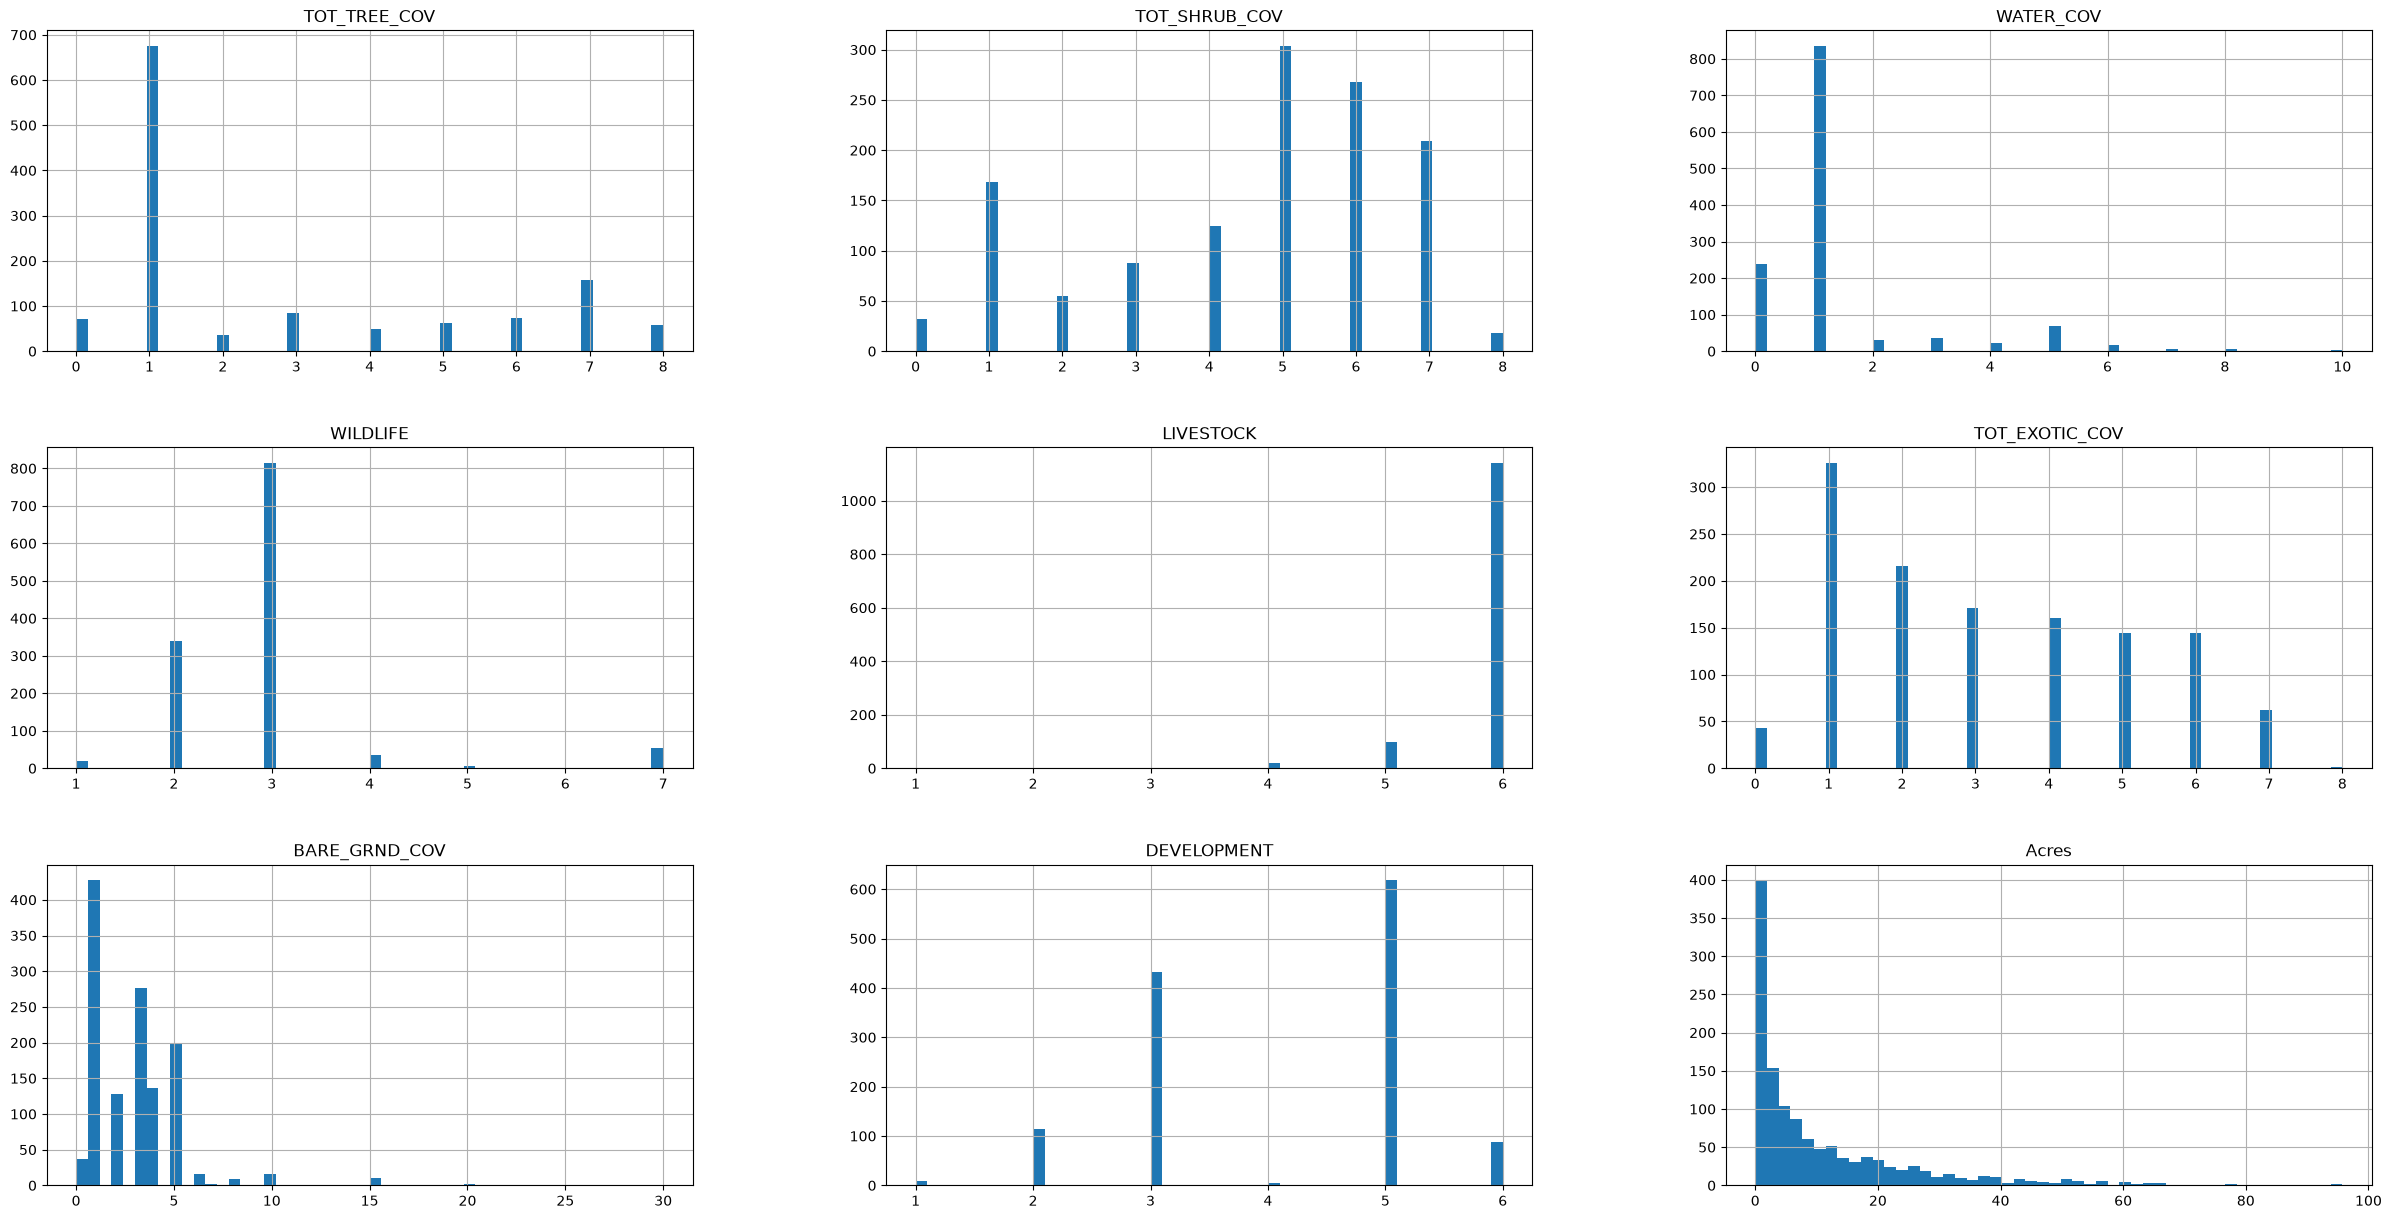

In [170]:
x.hist(bins=50, figsize=(30,15))

Next I am going to encode my categorical features. I am using one-hot encoding becuase though most of them are ordinal, they do not have set ratio variations and therefore are not fit for ordinal encoding.

Since the data does not have descriptive category names, I will set them myself. I am doing so using the documentation provided by the Washington State Geospatial Open Data portal's documentation. First, I will check the order of the categories with .categories_ to make sure I align them properly. I used .index to match the indexes of the encoded variables to the original dataframe. This way when I merge them they will all correlate.

In [171]:
import sklearn

encoder = sklearn.preprocessing.OneHotEncoder()

In [172]:
wildlife = x[['WILDLIFE']]
encoder.fit(wildlife)
print(encoder.categories_)

[array([1., 2., 3., 4., 5., 7.])]


In [173]:
wildlifeEncoded = pd.DataFrame(
    encoder.transform(wildlife).toarray(),
    columns=['heavyUngulate', 'moderateUngulate', 'lightUngulate', 'burrowing', 'beaver', 'other'],
    index=x.index
)


In [174]:
livestock = x[['LIVESTOCK']]
encoder.fit(livestock)
print(encoder.categories_)

[array([1., 2., 3., 4., 5., 6.])]


In [175]:
livestockEncoded = pd.DataFrame(
    encoder.transform(livestock).toarray(),
    columns=['activeHeavyGrazing', 'activeModerateGrazing', 'activeLightGrazing', 'heavyPastGrazing', 'lightPastGrazing', 'noGrazing'],
    index=x.index
)

In [176]:
development = x[['DEVELOPMENT']]
encoder.fit(development)
print(encoder.categories_)

[array([1., 2., 3., 4., 5., 6.])]


In [177]:
developmentEncoded = pd.DataFrame(
    encoder.transform(development).toarray(),
    columns=['activeFacilities', 'roads', 'trails', 'abandondedFacilities', 'none', 'multiple'],
    index=x.index
)

now that my columns are encoded I will drop the old versions and merge the new ones

In [179]:
x = x.drop(columns=['WILDLIFE', 'LIVESTOCK', 'DEVELOPMENT'])

In [181]:
x = pd.concat([x, wildlifeEncoded, livestockEncoded, developmentEncoded], axis=1)

In [182]:
x

,TOT_TREE_COV,TOT_SHRUB_COV,WATER_COV,TOT_EXOTIC_COV,BARE_GRND_COV,Acres,heavyUngulate,moderateUngulate,lightUngulate,burrowing,...,activeLightGrazing,heavyPastGrazing,lightPastGrazing,noGrazing,activeFacilities,roads,trails,abandondedFacilities,none,multiple
724,5.0,7.0,3.0,6.0,5.0,2.140156,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
728,5.0,5.0,4.0,6.0,3.0,1.397389,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
730,5.0,7.0,3.0,6.0,3.0,2.492270,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
746,6.0,5.0,3.0,3.0,3.0,3.489163,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1762,3.0,5.0,3.0,5.0,5.0,22.165016,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6149,4.0,6.0,3.0,1.0,1.0,1.277840,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
6153,6.0,7.0,1.0,1.0,2.0,5.705624,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
6154,6.0,6.0,1.0,1.0,3.0,10.849202,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
6165,7.0,2.0,5.0,1.0,3.0,29.106627,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


here im using a min max scalar to scale my data.

In [183]:
scalar = sklearn.preprocessing.MinMaxScaler()
x = pd.DataFrame(scalar.fit_transform(x), columns=x.columns)

Here I'm checking for correlation in my columns

In [188]:
print(x.corr())

                       TOT_TREE_COV  TOT_SHRUB_COV  WATER_COV  TOT_EXOTIC_COV  \
TOT_TREE_COV               1.000000       0.152763  -0.008206       -0.376624   
TOT_SHRUB_COV              0.152763       1.000000   0.048561       -0.033457   
WATER_COV                 -0.008206       0.048561   1.000000       -0.124731   
TOT_EXOTIC_COV            -0.376624      -0.033457  -0.124731        1.000000   
BARE_GRND_COV             -0.205721       0.020206  -0.172533        0.243811   
Acres                      0.039073       0.149415  -0.194187        0.125298   
heavyUngulate              0.031227       0.082334   0.039753        0.013024   
moderateUngulate           0.172705      -0.112902   0.206086        0.046595   
lightUngulate             -0.190852       0.070455  -0.329745        0.044649   
burrowing                  0.076484      -0.011752  -0.085171       -0.124753   
beaver                     0.104186       0.013329   0.200509        0.060324   
other                     -0

In [187]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3)
clusters = kmeans.fit_predict(x)
print(pd.Series(clusters).value_counts())

2    488
1    439
0    340
Name: count, dtype: int64


# testing

In [190]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

In [191]:
xTrain, xTest, yTrain, yTest = train_test_split(x, y, test_size=0.2, stratify=y)
model = RandomForestClassifier(n_estimators=42)
model.fit(xTrain, yTrain)
yPred = model.predict(xTest)
print(accuracy_score(yTest, yPred))
print(confusion_matrix(yTest, yPred))

0.7519685039370079
[[81  9  3  0]
 [15 70 10  1]
 [ 2 15 32  1]
 [ 0  2  5  8]]


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


<Axes: >

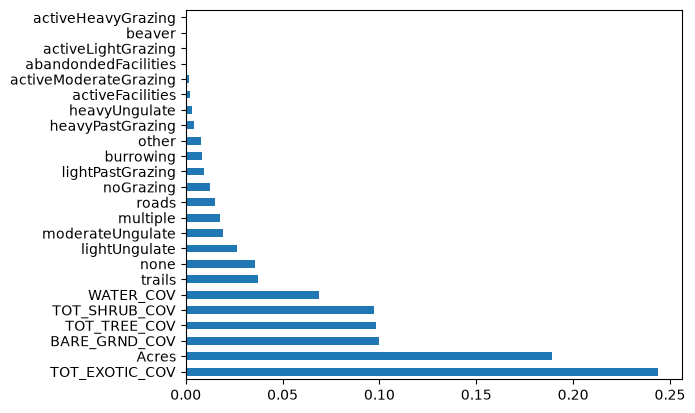

In [192]:
pd.Series(model.feature_importances_, index=x.columns).sort_values(ascending=False).plot(kind='barh')